In [6]:
import pandas as pd

df = pd.read_csv("heart_attack.csv")
print(df.shape)
print(df["HeartDiseaseorAttack"].value_counts(normalize=True))
df.head()

(129998, 16)
HeartDiseaseorAttack
0    0.906491
1    0.093509
Name: proportion, dtype: float64


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,HvyAlcoholConsump,MentHlth,PhysHlth,Sex,Age,Education,Income
0,0,1,1,1,40.0,1,0,0,0,0,18,15,0,9,4,3
1,0,0,0,0,25.0,1,0,0,1,0,0,0,0,7,6,1
2,0,1,1,1,28.0,0,0,0,0,0,30,30,0,9,4,8
3,0,1,0,1,27.0,0,0,0,1,0,0,0,0,11,3,6
4,0,1,1,1,24.0,0,0,0,1,0,3,0,0,11,5,4


In [ ]:
import matplotlib.pyplot as plt
print("Missing values per column:"); print(df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())
print(df.describe().T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
vc = df["HeartDiseaseorAttack"].value_counts()
ax[0].bar(["No (0)", "Yes (1)"], vc.values, color=["#4C72B0", "#C44E52"]); ax[0].set_title("Class distribution")
c = df.corr()["HeartDiseaseorAttack"].drop("HeartDiseaseorAttack").sort_values()
ax[1].barh(c.index, c.values); ax[1].set_title("Correlation with target")
plt.tight_layout(); plt.show()
print(c.round(3))

### Split and scale
10 rows with missing BMI are dropped (negligible). Stratified 80/20 split keeps the 9.35% positive rate. The scaler is fitted on the training set only to avoid data leakage.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Only 10 missing values (all in BMI), so dropping those rows is fine
df = df.dropna()

X = df.drop(columns=["HeartDiseaseorAttack"])
y = df["HeartDiseaseorAttack"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit on train only
X_test_scaled = scaler.transform(X_test)

In [9]:
print(X_train_scaled.shape, X_test_scaled.shape)
print(y_train.mean(), y_test.mean())

(103990, 15) (25998, 15)
0.09350899124915857 0.09350719286098931


## 1.2 Models and 1.3 Evaluation
Metrics: accuracy, precision, recall, F1, confusion matrix and ROC AUC. Because only 9.35% of cases are positive, accuracy is misleading, so recall, F1 and AUC are prioritised.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

# Create the model
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Train
log_reg.fit(X_train_scaled, y_train)

# Predict
y_pred = log_reg.predict(X_test_scaled)

# Evaluate
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1       :", f1_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred))

y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]
print("ROC AUC  :", roc_auc_score(y_test, y_proba))

Accuracy : 0.9063389491499346
Precision: 0.4956896551724138
Recall   : 0.09461127108185932
F1       : 0.15889464594127806

Confusion matrix:
 [[23333   234]
 [ 2201   230]]

               precision    recall  f1-score   support

           0       0.91      0.99      0.95     23567
           1       0.50      0.09      0.16      2431

    accuracy                           0.91     25998
   macro avg       0.70      0.54      0.55     25998
weighted avg       0.87      0.91      0.88     25998

ROC AUC  : 0.831412578894726


In [11]:
log_reg_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
log_reg_bal.fit(X_train_scaled, y_train)

y_pred_bal = log_reg_bal.predict(X_test_scaled)
y_proba_bal = log_reg_bal.predict_proba(X_test_scaled)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_bal))
print("Precision:", precision_score(y_test, y_pred_bal))
print("Recall   :", recall_score(y_test, y_pred_bal))
print("F1       :", f1_score(y_test, y_pred_bal))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred_bal))
print("ROC AUC  :", roc_auc_score(y_test, y_proba_bal))

Accuracy : 0.7358258327563659
Precision: 0.23086255004246026
Recall   : 0.7828054298642534
F1       : 0.35656735994004124

Confusion matrix:
 [[17227  6340]
 [  528  1903]]
ROC AUC  : 0.8318026375941356


In [12]:
results = {
    "LogReg (baseline)": {"Accuracy": accuracy_score(y_test, y_pred), "Precision": precision_score(y_test, y_pred),
                          "Recall": recall_score(y_test, y_pred), "F1": f1_score(y_test, y_pred),
                          "ROC AUC": roc_auc_score(y_test, y_proba)},
    "LogReg (balanced)": {"Accuracy": accuracy_score(y_test, y_pred_bal), "Precision": precision_score(y_test, y_pred_bal),
                          "Recall": recall_score(y_test, y_pred_bal), "F1": f1_score(y_test, y_pred_bal),
                          "ROC AUC": roc_auc_score(y_test, y_proba_bal)},
}
pd.DataFrame(results).T.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
LogReg (baseline),0.906,0.496,0.095,0.159,0.831
LogReg (balanced),0.736,0.231,0.783,0.357,0.832


In [13]:
from sklearn.tree import DecisionTreeClassifier

def evaluate(name, model):
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba),
    }
    print(name)
    print(confusion_matrix(y_test, pred), "\n")

# 1. Default tree (no depth limit)
evaluate("DecTree (default)", DecisionTreeClassifier(random_state=42))

# 2. Depth-limited tree
evaluate("DecTree (max_depth=5)", DecisionTreeClassifier(max_depth=5, random_state=42))

# 3. Depth-limited + balanced class weights
evaluate("DecTree (depth=5, balanced)",
         DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))

pd.DataFrame(results).T.round(3)

DecTree (default)
[[21575  1992]
 [ 1777   654]] 

DecTree (max_depth=5)
[[23518    49]
 [ 2354    77]] 

DecTree (depth=5, balanced)
[[17110  6457]
 [  651  1780]] 



,Accuracy,Precision,Recall,F1,ROC AUC
LogReg (baseline),0.906,0.496,0.095,0.159,0.831
LogReg (balanced),0.736,0.231,0.783,0.357,0.832
DecTree (default),0.855,0.247,0.269,0.258,0.597
DecTree (max_depth=5),0.908,0.611,0.032,0.060,0.798
"DecTree (depth=5, balanced)",0.727,0.216,0.732,0.334,0.799


In [14]:
from sklearn.ensemble import RandomForestClassifier

probas = {
    "LogReg (baseline)": y_proba,
    "LogReg (balanced)": y_proba_bal,
}

def evaluate(name, model):
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    probas[name] = proba
    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba),
    }
    print(name)
    print(confusion_matrix(y_test, pred), "\n")
    return model

# Default forest
rf = evaluate("RandForest (default)",
              RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))

# Regularized + balanced forest
rf_bal = evaluate("RandForest (balanced)",
                  RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=20,
                                         class_weight="balanced", random_state=42, n_jobs=-1))

pd.DataFrame(results).T.round(3)

RandForest (default)
[[23091   476]
 [ 2170   261]] 

RandForest (balanced)
[[17032  6535]
 [  504  1927]] 



,Accuracy,Precision,Recall,F1,ROC AUC
LogReg (baseline),0.906,0.496,0.095,0.159,0.831
LogReg (balanced),0.736,0.231,0.783,0.357,0.832
DecTree (default),0.855,0.247,0.269,0.258,0.597
DecTree (max_depth=5),0.908,0.611,0.032,0.060,0.798
"DecTree (depth=5, balanced)",0.727,0.216,0.732,0.334,0.799
RandForest (default),0.898,0.354,0.107,0.165,0.800
RandForest (balanced),0.729,0.228,0.793,0.354,0.833


In [ ]:
# Re-run the trees with the shared evaluate() so their probabilities are stored for the ROC / PR plots
evaluate("DecTree (default)", DecisionTreeClassifier(random_state=42))
evaluate("DecTree (max_depth=5)", DecisionTreeClassifier(max_depth=5, random_state=42))
evaluate("DecTree (depth=5, balanced)", DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42))

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from sklearn.utils.class_weight import compute_class_weight

tf.random.set_seed(42)
np.random.seed(42)

classes = np.unique(y_train)
cw = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes, cw))

ann = keras.Sequential([
    keras.layers.Input(shape=(X_train_scaled.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid"),
])
ann.compile(optimizer="adam", loss="binary_crossentropy",
            metrics=["accuracy", keras.metrics.AUC(name="auc")])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                           restore_best_weights=True)

history = ann.fit(X_train_scaled, y_train, validation_split=0.2, epochs=50,
                  batch_size=256, class_weight=class_weights,
                  callbacks=[early_stop], verbose=1)

proba_ann = ann.predict(X_test_scaled).ravel()
pred_ann = (proba_ann >= 0.5).astype(int)
probas["ANN (balanced)"] = proba_ann
results["ANN (balanced)"] = {
    "Accuracy": accuracy_score(y_test, pred_ann),
    "Precision": precision_score(y_test, pred_ann),
    "Recall": recall_score(y_test, pred_ann),
    "F1": f1_score(y_test, pred_ann),
    "ROC AUC": roc_auc_score(y_test, proba_ann),
}
print(confusion_matrix(y_test, pred_ann))
pd.DataFrame(results).T.round(3)

Epoch 1/50
325/325 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6934 - auc: 0.7906 - loss: 0.5545 - val_accuracy: 0.7023 - val_auc: 0.8325 - val_loss: 0.5135
Epoch 2/50
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7007 - auc: 0.8194 - loss: 0.5191 - val_accuracy: 0.6988 - val_auc: 0.8344 - val_loss: 0.5113
Epoch 3/50
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7053 - auc: 0.8258 - loss: 0.5099 - val_accuracy: 0.7081 - val_auc: 0.8348 - val_loss: 0.5037
Epoch 4/50
325/325 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7090 - auc: 0.8270 - loss: 0.5088 - val_accuracy: 0.7059 - val_auc: 0.8352 - val_loss: 0.5019
Epoch 5/50
325/325 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.7062 - auc: 0.8291 - loss: 0.5055 - val_accuracy: 0.7075 - val_auc: 0.8353 - val_loss: 0.5032
Epoch 6/50
325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7074 - auc: 0.8296 - loss: 0.5055 - val_accuracy: 0.7045 - val_auc: 0.8354 - val_loss: 0.5048
Epoch 7/50
325/325 ━━━━━━━━━━━━━━━━━━━━ 

,Accuracy,Precision,Recall,F1,ROC AUC
LogReg (baseline),0.906,0.496,0.095,0.159,0.831
LogReg (balanced),0.736,0.231,0.783,0.357,0.832
DecTree (default),0.855,0.247,0.269,0.258,0.597
DecTree (max_depth=5),0.908,0.611,0.032,0.060,0.798
"DecTree (depth=5, balanced)",0.727,0.216,0.732,0.334,0.799
RandForest (default),0.898,0.354,0.107,0.165,0.800
RandForest (balanced),0.729,0.228,0.793,0.354,0.833
ANN (balanced),0.702,0.215,0.825,0.341,0.835


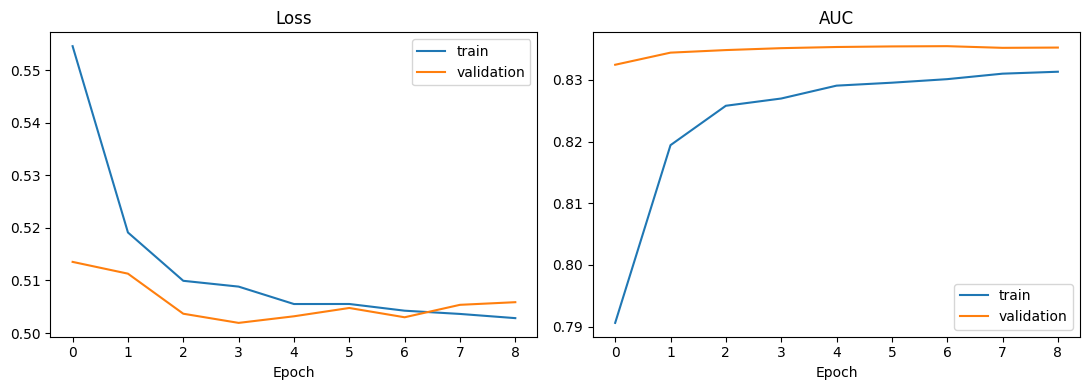

In [16]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["auc"], label="train"); ax[1].plot(history.history["val_auc"], label="validation")
ax[1].set_title("AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

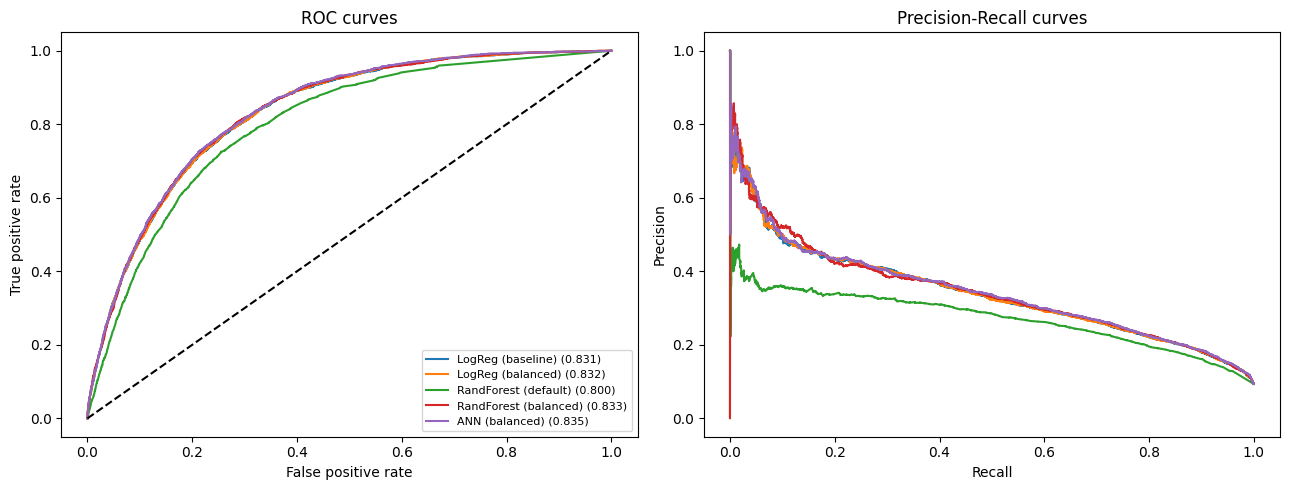

In [17]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rec, prec, label=name)
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC curves")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(fontsize=8)
ax[1].set_title("Precision-Recall curves"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
plt.tight_layout(); plt.show()

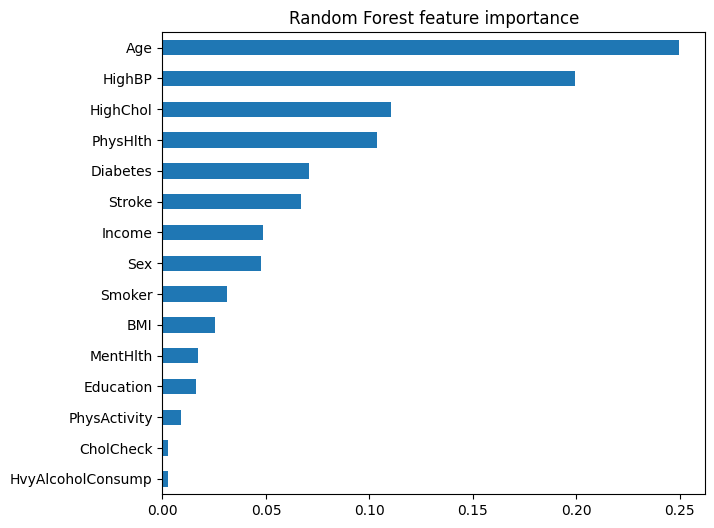

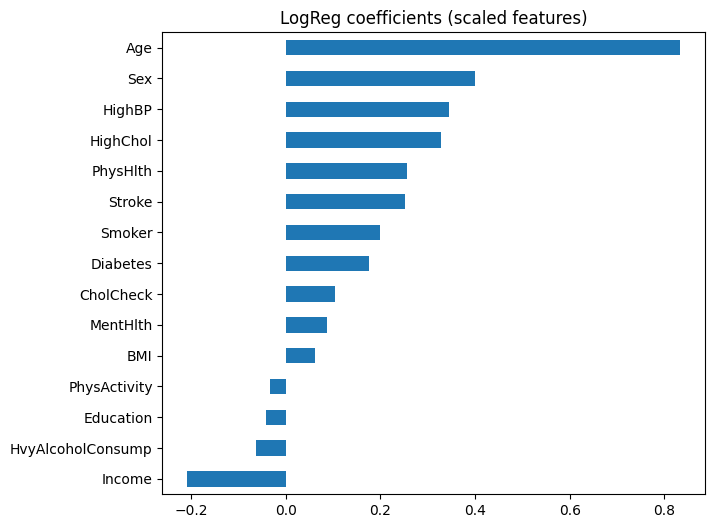

In [18]:
imp = pd.Series(rf_bal.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(7, 6), title="Random Forest feature importance")
plt.show()

# Logistic regression coefficients (direction of effect)
coef = pd.Series(log_reg_bal.coef_[0], index=X.columns).sort_values()
coef.plot(kind="barh", figsize=(7, 6), title="LogReg coefficients (scaled features)")
plt.show()

## 1.5 Improving the best model (Balanced Logistic Regression)
Two improvements, with all tuning decisions made on **training data only** (never the test set):
1. Decision-threshold optimisation
2. Feature engineering with polynomial / interaction terms

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve
from sklearn.preprocessing import PolynomialFeatures

def add_result(name, pred, proba):
    results[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                     "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                     "ROC AUC": roc_auc_score(y_test, proba)}
    print(name); print(confusion_matrix(y_test, pred), "\n")

from sklearn.model_selection import cross_val_predict, StratifiedKFold

def tuned_threshold(Xtr, Xte, max_iter=1000):
    # Out-of-fold probabilities from the BALANCED model, using training data only (no test leakage)
    mk = lambda: LogisticRegression(max_iter=max_iter, random_state=42, class_weight="balanced")
    oof = cross_val_predict(mk(), Xtr, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=42),
                            method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    t = thr[f1s.argmax()]
    model = mk().fit(Xtr, y_train)          # refit on the full training set
    p = model.predict_proba(Xte)[:, 1]
    return t, p, (p >= t).astype(int)

In [ ]:
# Improvement 1: threshold tuning of the balanced model (out-of-fold predictions, training data only)
t1, p_t1, pred_t1 = tuned_threshold(X_train_scaled, X_test_scaled)
print(f"Threshold chosen from out-of-fold training predictions: {t1:.3f}")
add_result("LogReg + threshold tuning", pred_t1, p_t1)

In [ ]:
# Improvement 2: degree-2 polynomial / interaction features (15 -> 135 features)
poly = PolynomialFeatures(2, include_bias=False)
Xp_train = poly.fit_transform(X_train_scaled); Xp_test = poly.transform(X_test_scaled)
sc2 = StandardScaler(); Xp_train = sc2.fit_transform(Xp_train); Xp_test = sc2.transform(Xp_test)
print("Feature count:", X_train_scaled.shape[1], "->", Xp_train.shape[1])

lr_poly = LogisticRegression(max_iter=2000, random_state=42, class_weight="balanced").fit(Xp_train, y_train)
add_result("LogReg + poly features", lr_poly.predict(Xp_test), lr_poly.predict_proba(Xp_test)[:, 1])

In [ ]:
# Evidence the poly gain is real: 5-fold CV ROC AUC, same folds for both models
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_lin = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
p_pol = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                      LogisticRegression(max_iter=2000, class_weight="balanced"))
s_lin = cross_val_score(p_lin, X, y, cv=cv5, scoring="roc_auc", n_jobs=-1)
s_pol = cross_val_score(p_pol, X, y, cv=cv5, scoring="roc_auc", n_jobs=-1)
print("Linear  :", s_lin.round(4), "mean", s_lin.mean().round(4))
print("Poly    :", s_pol.round(4), "mean", s_pol.mean().round(4))
print("Poly higher in", (s_pol > s_lin).sum(), "of 5 folds")

In [ ]:
# Both improvements combined
t2, p_t2, pred_t2 = tuned_threshold(Xp_train, Xp_test, max_iter=2000)
print(f"Threshold chosen from out-of-fold training predictions: {t2:.3f}")
add_result("LogReg + poly + threshold", pred_t2, p_t2)

In [ ]:
# Ideas that did NOT help (negative results, still worth reporting)
!pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV

Xs, ys = SMOTE(random_state=42).fit_resample(X_train_scaled, y_train)
sm = LogisticRegression(max_iter=1000, random_state=42).fit(Xs, ys)
add_result("LogReg + SMOTE", sm.predict(X_test_scaled), sm.predict_proba(X_test_scaled)[:, 1])

gs = GridSearchCV(LogisticRegression(max_iter=1000, class_weight="balanced"), {"C": [0.01, 0.1, 1, 10]},
                  scoring="roc_auc", cv=3, n_jobs=-1).fit(X_train_scaled, y_train)
print("Best C:", gs.best_params_, "| test AUC:", round(roc_auc_score(y_test, gs.predict_proba(X_test_scaled)[:, 1]), 4))

In [ ]:
names = ["LogReg (balanced)", "LogReg + threshold tuning", "LogReg + poly features", "LogReg + poly + threshold", "LogReg + SMOTE"]
imp_df = pd.DataFrame(results).T.loc[names].round(3)
display(imp_df)

imp_df[["Accuracy", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4), title="Effect of the improvements on the best model")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

In [20]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
scores = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc", n_jobs=-1)
print("LogReg 5-fold ROC AUC:", scores.round(3), "mean:", scores.mean().round(3))

LogReg 5-fold ROC AUC: [0.835 0.829 0.83  0.837 0.836] mean: 0.833


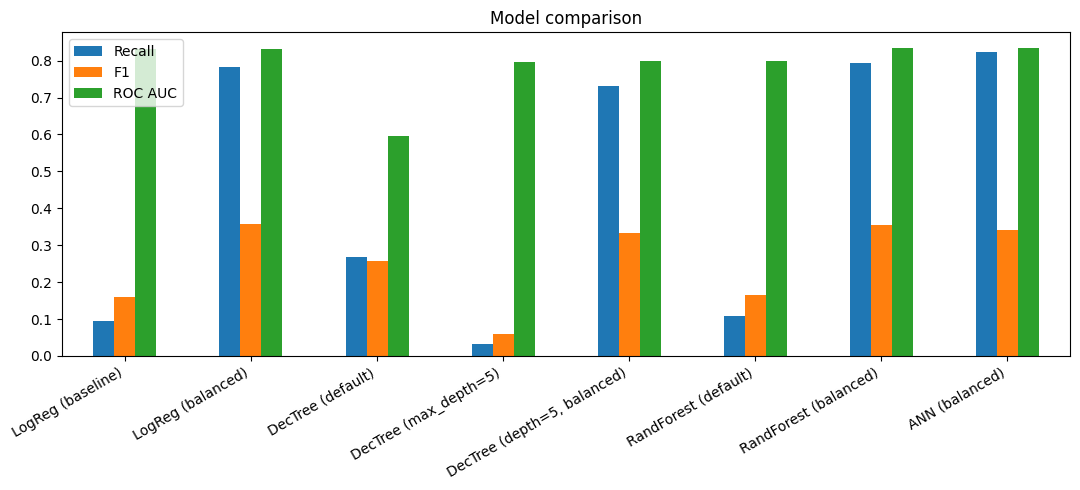

In [21]:
res_df = pd.DataFrame(results).T
res_df[["Recall", "F1", "ROC AUC"]].plot(kind="bar", figsize=(11, 5), title="Model comparison")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

## 1.4 Conclusion
- Accuracy is misleading (90.6% is achieved by always predicting "no"); models were compared on recall, F1 and ROC AUC.
- Balanced Logistic Regression is the best overall model (recall 0.783, F1 0.357, AUC 0.832). ANN, Random Forest and Logistic Regression are statistically indistinguishable on AUC (CV range 0.829-0.837).
- Threshold tuning (out-of-fold, training data only) and polynomial interaction features raise F1 to about 0.404.
- Limitation: self-reported survey data, so the model supports screening, not diagnosis.